In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('../')
print(sys.path)

['/home/thule/miniconda3/envs/open-clip-training/lib/python311.zip', '/home/thule/miniconda3/envs/open-clip-training/lib/python3.11', '/home/thule/miniconda3/envs/open-clip-training/lib/python3.11/lib-dynload', '', '/home/thule/miniconda3/envs/open-clip-training/lib/python3.11/site-packages', '../']


In [2]:
import matplotlib.pyplot as plt

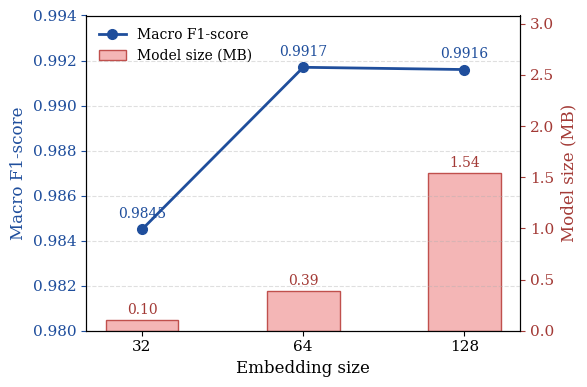

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# ---------------- Data ----------------
embedding_size = [32, 64, 128]
f1_score = [0.9845, 0.9917, 0.9916]
model_size_mb = [0.10, 0.39, 1.54]

# ---------------- Style ----------------
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

x = np.arange(len(embedding_size))   # evenly spaced categories
fig, ax1 = plt.subplots(figsize=(6, 4))

# Model size as bars (right axis)
ax2 = ax1.twinx()
bars = ax2.bar(x, model_size_mb, width=0.45, color="#f4b6b6", edgecolor="#c0504d",
               linewidth=1.0, label="Model size (MB)", zorder=1)
for xi, v in zip(x, model_size_mb):
    ax2.text(xi, v + 0.03, f"{v:.2f}", ha="center", va="bottom", fontsize=10, color="#a33a36")
ax2.set_ylabel("Model size (MB)", color="#a33a36")
ax2.tick_params(axis="y", colors="#a33a36")
ax2.set_ylim(0, max(model_size_mb) * 2.0)   # keeps bars below the F1 line

# F1-score as line (left axis), drawn on top of the bars
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)
line, = ax1.plot(x, f1_score, marker="o", markersize=7, linewidth=2,
                 color="#1f4e9c", label="Macro F1-score", zorder=3)
for xi, v in zip(x, f1_score):
    ax1.annotate(f"{v:.4f}", (xi, v), textcoords="offset points", xytext=(0, 8),
                 ha="center", fontsize=10, color="#1f4e9c")
ax1.set_ylabel("Macro F1-score", color="#1f4e9c")
ax1.tick_params(axis="y", colors="#1f4e9c")
ax1.set_ylim(0.980, 0.994)

ax1.set_xticks(x)
ax1.set_xticklabels(embedding_size)
ax1.set_xlabel("Embedding size")
ax1.grid(axis="y", linestyle="--", alpha=0.4)

# Combined legend
ax1.legend([line, bars], ["Macro F1-score", "Model size (MB)"], loc="upper left", frameon=False)

fig.tight_layout()
# fig.savefig("embedding_size_f1_model_size.pdf", bbox_inches="tight")   # vector, for LaTeX
fig.savefig("../images/plot_results/embedding_size_vs_f1_model_size.png", dpi=300, bbox_inches="tight")
plt.show()